
Dataset Loaded Successfully
Features Shape : (398, 7)
Target Shape   : (398, 1)

DATA CLEANING

Missing Values Before Cleaning:
displacement    0
cylinders       0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64

Missing Values After Cleaning:
displacement    0
cylinders       0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64

Linear Regression
Train MSE  : 11.66
Test MSE   : 8.2
Train RMSE : 3.41
Test RMSE  : 2.86
Train R²   : 0.814
Test R²    : 0.8475

Polynomial Degree 2
Train MSE  : 6.76
Test MSE   : 5.97
Train RMSE : 2.6
Test RMSE  : 2.44
Train R²   : 0.8922
Test R²    : 0.889

Polynomial Degree 3
Train MSE  : 3.65
Test MSE   : 13.94
Train RMSE : 1.91
Test RMSE  : 3.73
Train R²   : 0.9418
Test R²    : 0.7407

Polynomial Degree 5
Train MSE  : 0.0
Test MSE   : 4450.13
Train RMSE : 0.0
Test RMSE  : 66.71
Train R²   : 1.0
Test R²    : -81.7678

Ridge Regression
Train MSE  : 5

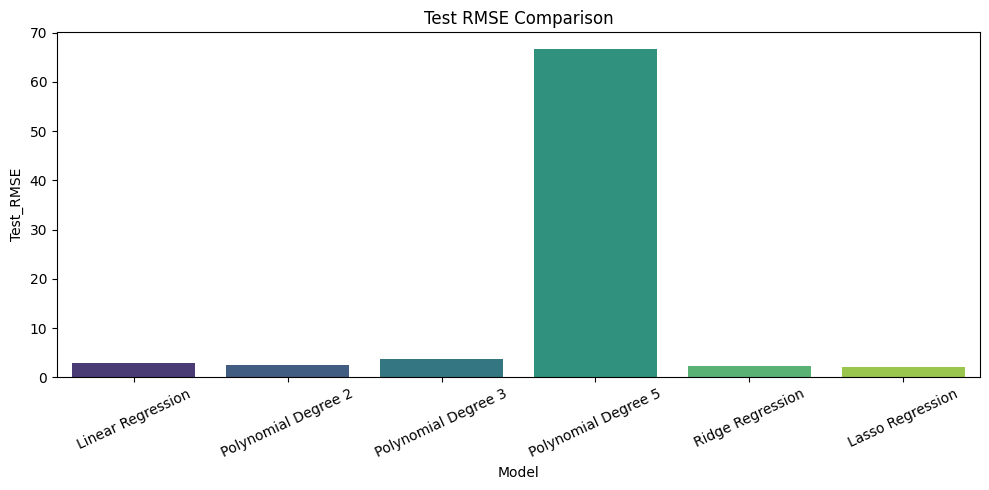

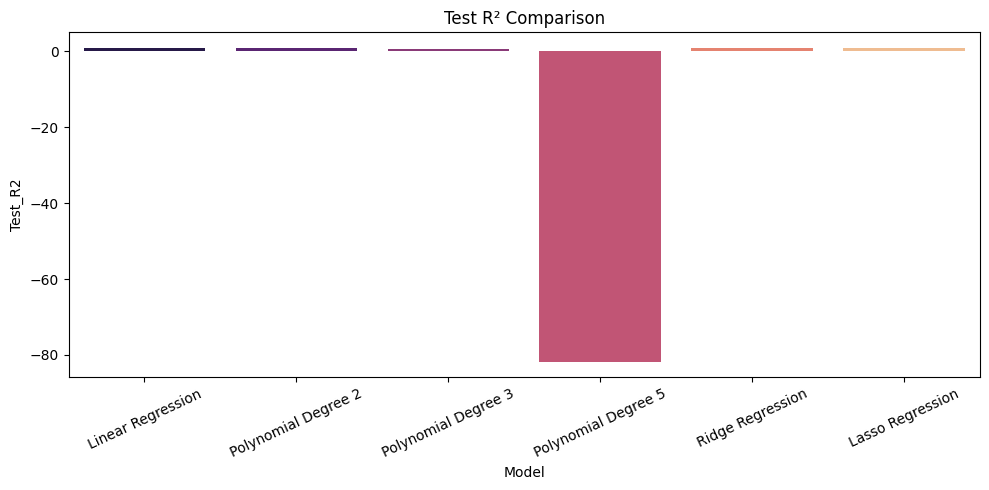

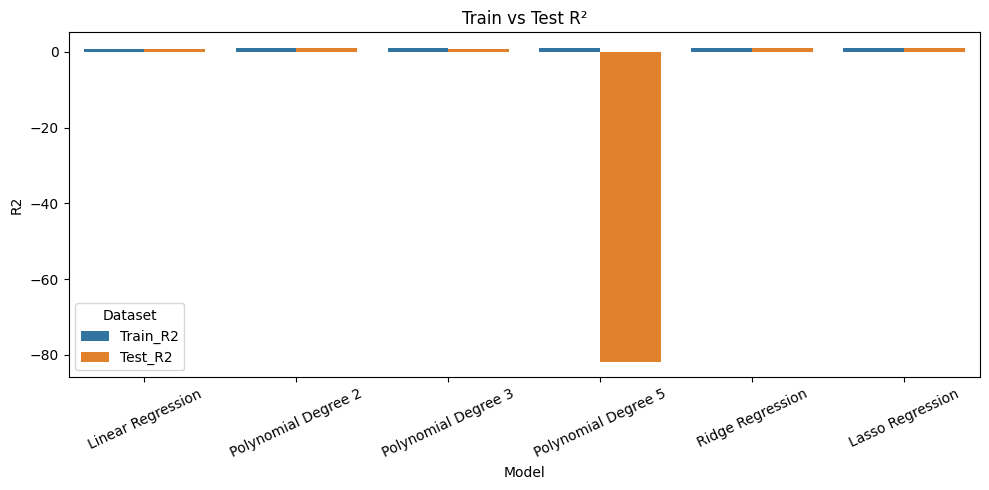

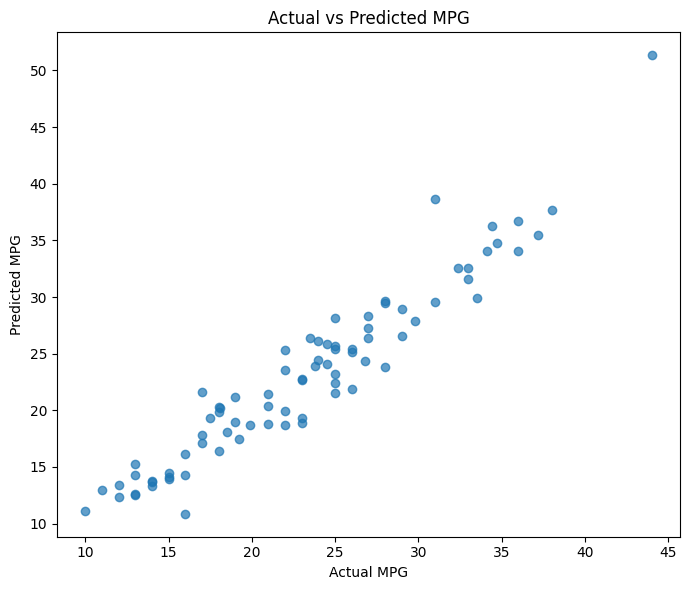



UNDERFITTING AND OVERFITTING ANALYSIS

Linear Regression
Observation: Good Generalization

Polynomial Degree 2
Observation: Good Generalization

Polynomial Degree 3
Observation: Possible Overfitting

Polynomial Degree 5
Observation: Possible Underfitting

Ridge Regression
Observation: Good Generalization

Lasso Regression
Observation: Good Generalization


METRIC EXPLANATIONS

MSE (Mean Squared Error)
- Average squared difference between actual and predicted values.
- Smaller is better.

RMSE (Root Mean Squared Error)
- Square root of MSE.
- Easier to interpret because it uses the same unit as MPG.
- Smaller is better.

R² Score
- Indicates how much variation in MPG is explained by the model.
- Closer to 1 is better.



RIDGE VS LASSO

RIDGE REGRESSION:
- Uses L2 Regularization.
- Shrinks coefficient values.
- Helps reduce overfitting.
- Keeps all features.

LASSO REGRESSION:
- Uses L1 Regularization.
- Shrinks some coefficients to zero.
- Performs feature selection.
- Produces simpl

In [3]:
# ==========================================================
# ASSIGNMENT 2
# Regression Complexity and Regularization
# Dataset: Auto MPG (UCI Repository)
# ==========================================================

!pip install -q ucimlrepo

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)

from sklearn.metrics import (
    mean_squared_error,
    r2_score
)

# ==========================================================
# 1. Load Dataset
# ==========================================================

print("="*60)
print("Downloading Auto MPG Dataset from UCI")
print("="*60)

auto_mpg = fetch_ucirepo(id=9)

X = auto_mpg.data.features
y = auto_mpg.data.targets

print("\nDataset Loaded Successfully")
print("Features Shape :", X.shape)
print("Target Shape   :", y.shape)

# ==========================================================
# 2. Data Cleaning
# ==========================================================

print("\n" + "="*60)
print("DATA CLEANING")
print("="*60)

print("\nMissing Values Before Cleaning:")
print(X.isnull().sum())

# Keep numeric columns only
X = X.select_dtypes(include=['int64','float64'])

# Median Imputation
imputer = SimpleImputer(strategy="median")

X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns
)

print("\nMissing Values After Cleaning:")
print(X.isnull().sum())

# ==========================================================
# 3. Train Test Split
# ==========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# ==========================================================
# 4. Evaluation Function
# ==========================================================

results = []

def evaluate_model(model_name, model):

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_mse = mean_squared_error(y_train, train_pred)
    test_mse = mean_squared_error(y_test, test_pred)

    train_rmse = np.sqrt(train_mse)
    test_rmse = np.sqrt(test_mse)

    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)

    results.append({
        "Model": model_name,
        "Train_MSE": train_mse,
        "Test_MSE": test_mse,
        "Train_RMSE": train_rmse,
        "Test_RMSE": test_rmse,
        "Train_R2": train_r2,
        "Test_R2": test_r2
    })

    print("\n" + "="*60)
    print(model_name)
    print("="*60)

    print("Train MSE  :", round(train_mse,2))
    print("Test MSE   :", round(test_mse,2))
    print("Train RMSE :", round(train_rmse,2))
    print("Test RMSE  :", round(test_rmse,2))
    print("Train R²   :", round(train_r2,4))
    print("Test R²    :", round(test_r2,4))

# ==========================================================
# 5. Linear Regression
# ==========================================================

linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

evaluate_model("Linear Regression", linear_model)

# ==========================================================
# 6. Polynomial Regression Degree 2
# ==========================================================

poly2 = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("model", LinearRegression())
])

evaluate_model("Polynomial Degree 2", poly2)

# ==========================================================
# 7. Polynomial Regression Degree 3
# ==========================================================

poly3 = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=3, include_bias=False)),
    ("model", LinearRegression())
])

evaluate_model("Polynomial Degree 3", poly3)

# ==========================================================
# 8. Polynomial Regression Degree 5
# ==========================================================

poly5 = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=5, include_bias=False)),
    ("model", LinearRegression())
])

evaluate_model("Polynomial Degree 5", poly5)

# ==========================================================
# 9. Ridge Regression
# ==========================================================

ridge_model = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=3, include_bias=False)),
    ("model", Ridge(alpha=10))
])

evaluate_model("Ridge Regression", ridge_model)

# ==========================================================
# 10. Lasso Regression
# ==========================================================

lasso_model = Pipeline([
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(degree=3, include_bias=False)),
    ("model", Lasso(alpha=0.1))
])

evaluate_model("Lasso Regression", lasso_model)

# ==========================================================
# 11. Comparison Results
# ==========================================================

results_df = pd.DataFrame(results)

print("\n")
print("="*60)
print("COMPARISON RESULTS")
print("="*60)

print(results_df)

# ==========================================================
# 12. RMSE Comparison Plot
# ==========================================================

plt.figure(figsize=(10,5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Test_RMSE",
    palette="viridis"
)

plt.xticks(rotation=25)
plt.title("Test RMSE Comparison")
plt.tight_layout()
plt.show()

# ==========================================================
# 13. R² Comparison Plot
# ==========================================================

plt.figure(figsize=(10,5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Test_R2",
    palette="magma"
)

plt.xticks(rotation=25)
plt.title("Test R² Comparison")
plt.tight_layout()
plt.show()

# ==========================================================
# 14. Train vs Test R² Plot
# ==========================================================

plot_df = results_df.melt(
    id_vars="Model",
    value_vars=["Train_R2","Test_R2"],
    var_name="Dataset",
    value_name="R2"
)

plt.figure(figsize=(10,5))

sns.barplot(
    data=plot_df,
    x="Model",
    y="R2",
    hue="Dataset"
)

plt.xticks(rotation=25)
plt.title("Train vs Test R²")
plt.tight_layout()
plt.show()

# ==========================================================
# 15. Actual vs Predicted Plot
# ==========================================================

ridge_model.fit(X_train, y_train)

pred = ridge_model.predict(X_test)

plt.figure(figsize=(7,6))
plt.scatter(y_test, pred, alpha=0.7)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Actual vs Predicted MPG")

plt.tight_layout()
plt.show()

# ==========================================================
# 16. Underfitting and Overfitting Analysis
# ==========================================================

print("\n")
print("="*60)
print("UNDERFITTING AND OVERFITTING ANALYSIS")
print("="*60)

best_r2 = results_df["Test_R2"].max()

for index, row in results_df.iterrows():

    gap = row["Train_R2"] - row["Test_R2"]

    print(f"\n{row['Model']}")

    if row["Test_R2"] < 0.70:
        print("Observation: Possible Underfitting")

    elif gap > 0.15:
        print("Observation: Possible Overfitting")

    else:
        print("Observation: Good Generalization")

# ==========================================================
# 17. Explain Metrics
# ==========================================================

print("\n")
print("="*60)
print("METRIC EXPLANATIONS")
print("="*60)

print("""
MSE (Mean Squared Error)
- Average squared difference between actual and predicted values.
- Smaller is better.

RMSE (Root Mean Squared Error)
- Square root of MSE.
- Easier to interpret because it uses the same unit as MPG.
- Smaller is better.

R² Score
- Indicates how much variation in MPG is explained by the model.
- Closer to 1 is better.
""")

# ==========================================================
# 18. Regularization Impact
# ==========================================================

print("\n")
print("="*60)
print("RIDGE VS LASSO")
print("="*60)

print("""
RIDGE REGRESSION:
- Uses L2 Regularization.
- Shrinks coefficient values.
- Helps reduce overfitting.
- Keeps all features.

LASSO REGRESSION:
- Uses L1 Regularization.
- Shrinks some coefficients to zero.
- Performs feature selection.
- Produces simpler models.
""")

# ==========================================================
# 19. Final Conclusion
# ==========================================================

print("\n")
print("="*60)
print("CONCLUSION")
print("="*60)

print("""
1. Auto MPG dataset was selected as a nonlinear regression problem.

2. Linear Regression provided the baseline performance.

3. Polynomial Regression improved performance by capturing
   nonlinear relationships between vehicle attributes and MPG.

4. Higher polynomial degrees increased model complexity and
   may show overfitting when training performance becomes
   much better than testing performance.

5. Ridge Regression reduced coefficient magnitudes and
   improved generalization.

6. Lasso Regression simplified the model through feature
   selection and coefficient shrinkage.

7. The best model is the one that achieves high Test R²
   with a small difference between Train and Test R²,
   indicating a good balance between bias and variance.
""")
